# Smart Vitals 03: does it work as well for everyone? (fairness, Output 3)
**CMS22301 · Smart Vitals IPMS**

The ethics checklist asks: *does the model work as well for every risk group, and for patients with and without diabetes?* Notebook 02 broke its results down on only 16 test patients, too few to say much about a group. Here **every one of the 80 patients is tested once, while unseen**:

- **Outer loop:** 5 folds over patients. Each fold's patients are held out, and a model is trained on the other 64.
- **Inner loop:** inside those 64, another grouped cross-validation tunes the Critical threshold (to find 92% of Critical readings, as in notebook 02). The held-out patients are never used for tuning.
- **What is scored is the system as deployed:** model v2's recipe (gradient boosting + last-5 median + SpO₂ scale) **plus the NEWS2-inspired rule as a safety net** (A22).

Two views:
1. **Readings:** recall for Critical and false alarms per 100 Normal readings, with 95% confidence intervals from resampling *patients* (readings from one patient are not independent).
2. **Episodes:** a run of consecutive Critical minutes is one event a clinician needs to hear about. An episode is *found* if the system calls any of its readings Critical. A missed episode is a patient nobody was told about.

No real patient data: everything comes from `simulator/` (seed 42, `data/DATA_CARD.md`).

In [1]:
from pathlib import Path
import sys
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.evaluation import critical_threshold_for_recall
from src.features import SINGLE_FEATURES, WINDOW_FEATURES, add_patient_settings, add_window_features, clean_readings
from src.labelling import label
from src.model import predict_with_threshold

SEED = 42
TUNING_TARGET = 0.92
FEATURES = SINGLE_FEATURES + WINDOW_FEATURES
make_model = lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)  # noqa: E731

## Step 1 · Data, cleaned and prepared exactly as the API does it

In [2]:
vitals = pd.read_csv(ROOT / "data" / "sim_vitals.csv")
patients = pd.read_csv(ROOT / "data" / "sim_patients.csv")
truth = pd.read_csv(ROOT / "data" / "sim_ground_truth.csv", usecols=["msg_id", "episode_type"])
df, _ = clean_readings(vitals)
df = add_window_features(add_patient_settings(df, patients)).merge(truth, on="msg_id", how="left")
df = df.merge(patients[["patient_id", "age_band", "hypertension", "arrhythmia", "copd", "risk_group"]], on="patient_id")
df = df.sort_values(["patient_id", "measured_ts"]).reset_index(drop=True)
print(f"{len(df):,} readings from {df['patient_id'].nunique()} patients")

342,931 readings from 80 patients


## Step 2 · Nested cross-validation: every patient tested once, unseen
This takes about a minute.

In [3]:
outer = GroupKFold(n_splits=5)
inner = GroupKFold(n_splits=4)
df["pred"] = ""
thresholds = []
for fold, (train_idx, test_idx) in enumerate(outer.split(df, groups=df["patient_id"]), start=1):
    train = df.iloc[train_idx]
    p_oof = np.zeros(len(train))
    for tr, va in inner.split(train, groups=train["patient_id"]):
        m = make_model().fit(train.iloc[tr][FEATURES], train.iloc[tr]["status"])
        p_oof[va] = m.predict_proba(train.iloc[va][FEATURES])[:, list(m.classes_).index("Critical")]
    threshold = critical_threshold_for_recall(train["status"], p_oof, TUNING_TARGET)
    model = make_model().fit(train[FEATURES], train["status"])
    test = df.iloc[test_idx]
    pred = predict_with_threshold(model, test[FEATURES], threshold)
    rule = label(test["heart_rate_med5"], test["spo2_med5"], test["systolic_bp_med5"], test["temperature_med5"],
                 test["glucose_med5"], test["spo2_scale"])[1]
    df.loc[df.index[test_idx], "pred"] = np.where(rule == "Critical", "Critical", pred)  # safety net (A22)
    thresholds.append(threshold)
    print(f"fold {fold}: {test['patient_id'].nunique()} unseen patients, threshold {threshold:.3f}")

fold 1: 16 unseen patients, threshold 0.165


fold 2: 16 unseen patients, threshold 0.327


fold 3: 16 unseen patients, threshold 0.158


fold 4: 16 unseen patients, threshold 0.266


fold 5: 16 unseen patients, threshold 0.157


## Step 3 · Results per patient, then per group
Counting per patient first makes the confidence intervals honest: a bootstrap resamples **patients**, not minutes.

In [4]:
df["critical"] = df["status"] == "Critical"
df["found"] = df["critical"] & (df["pred"] == "Critical")
df["normal"] = df["status"] == "Normal"
df["false_alarm"] = df["normal"] & (df["pred"] == "Critical")

# Episodes: consecutive Critical minutes of one patient (a gap of more than 5 minutes starts a new one)
crit = df[df["critical"]].copy()
gap = crit.groupby("patient_id")["measured_ts"].diff() > pd.Timedelta(minutes=5)
crit["episode"] = (crit["patient_id"].ne(crit["patient_id"].shift()) | gap).cumsum()
episodes = crit.groupby("episode").agg(patient_id=("patient_id", "first"), found=("found", "any"),
                                       minutes=("found", "size"), kind=("episode_type", "first"))

per_patient = df.groupby("patient_id").agg(critical=("critical", "sum"), found=("found", "sum"),
                                            normal=("normal", "sum"), false_alarm=("false_alarm", "sum"))
per_patient["episodes"] = episodes.groupby("patient_id").size().reindex(per_patient.index, fill_value=0)
per_patient["episodes_found"] = episodes.groupby("patient_id")["found"].sum().reindex(per_patient.index, fill_value=0)
per_patient = per_patient.join(patients.set_index("patient_id")[
    ["risk_group", "diabetes", "spo2_scale", "age_band", "hypertension", "arrhythmia", "copd"]])
print(f"Overall: recall for Critical {per_patient['found'].sum() / per_patient['critical'].sum():.3f}, "
      f"{100 * per_patient['false_alarm'].sum() / per_patient['normal'].sum():.2f} false alarms per 100 Normal, "
      f"{int(per_patient['episodes_found'].sum())} of {int(per_patient['episodes'].sum())} episodes found")

Overall: recall for Critical 0.970, 0.88 false alarms per 100 Normal, 186 of 201 episodes found


In [5]:
rng = np.random.default_rng(SEED)


def summarise(rows: pd.DataFrame, boot: int = 2000) -> dict:
    """Totals for a group of patients, with 95% intervals from resampling those patients."""
    sums = rows[["critical", "found", "normal", "false_alarm", "episodes", "episodes_found"]].to_numpy(float)
    total = sums.sum(axis=0)
    picks = rng.integers(0, len(rows), size=(boot, len(rows)))
    resampled = sums[picks].sum(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = resampled[:, 1] / resampled[:, 0]
        fa = 100 * resampled[:, 3] / resampled[:, 2]
    low_r, high_r = np.nanpercentile(recall, [2.5, 97.5]) if total[0] else (np.nan, np.nan)
    low_f, high_f = np.nanpercentile(fa, [2.5, 97.5])
    return {"patients": len(rows), "Critical readings": int(total[0]),
            "recall Critical": total[1] / total[0] if total[0] else np.nan, "recall low": low_r, "recall high": high_r,
            "false alarms /100 Normal": 100 * total[3] / total[2], "FA low": low_f, "FA high": high_f,
            "episodes": int(total[4]), "episodes found": int(total[5])}


GROUPS = {"risk group": "risk_group", "diabetes": "diabetes", "SpO₂ scale": "spo2_scale", "age band": "age_band",
          "hypertension": "hypertension", "arrhythmia": "arrhythmia", "COPD-like": "copd"}
rows = [{"group": "everyone", "value": "all", **summarise(per_patient)}]
for name, column in GROUPS.items():
    for value, members in per_patient.groupby(column):
        rows.append({"group": name, "value": str(value), **summarise(members)})
fairness = pd.DataFrame(rows)
show = fairness.round({"recall Critical": 3, "recall low": 3, "recall high": 3, "false alarms /100 Normal": 2,
                       "FA low": 2, "FA high": 2})
print(show.to_string(index=False))

       group  value  patients  Critical readings  recall Critical  recall low  recall high  false alarms /100 Normal  FA low  FA high  episodes  episodes found
    everyone    all        80              15055            0.970       0.955        0.981                      0.88    0.60     1.20       201             186
  risk group   High        16               6139            0.982       0.969        0.990                      1.65    1.04     2.33        55              55
  risk group    Low        36               3956            0.947       0.908        0.977                      0.86    0.39     1.43       103              93
  risk group Medium        28               4960            0.972       0.952        0.986                      0.50    0.24     0.81        43              38
    diabetes      0        60              10407            0.974       0.962        0.984                      0.86    0.52     1.27       135             123
    diabetes      1        20           

## Step 4 · The picture (for the report)
Recall for Critical by group, with 95% intervals. The dashed line is the target (0.90, A5). **Wide intervals mean too few patients to be sure**, not a better or worse model.

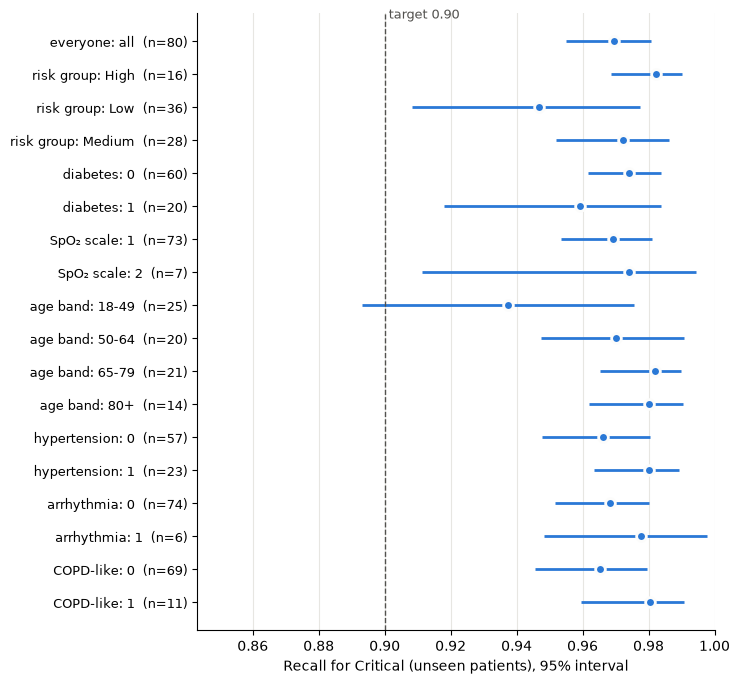

In [6]:
plot = fairness[fairness["Critical readings"] > 0].reset_index(drop=True)
labels = [f"{g}: {v}  (n={n})" for g, v, n in zip(plot["group"], plot["value"], plot["patients"], strict=True)]
fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(plot) + 1.2))
y = np.arange(len(plot))[::-1]
ax.hlines(y, plot["recall low"], plot["recall high"], color="#2a78d6", linewidth=2)
ax.plot(plot["recall Critical"], y, "o", color="#2a78d6", markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.axvline(0.90, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.90, len(plot) - 0.4, " target 0.90", color="#52514e", fontsize=9, va="bottom")
ax.set_yticks(y, labels, fontsize=9)
ax.set_xlabel("Recall for Critical (unseen patients), 95% interval")
ax.set_xlim(max(0.5, float(np.nanmin(plot["recall low"])) - 0.05), 1.0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e7e6e2", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(ROOT / "docs" / "results" / "fairness_recall.png", dpi=150)
plt.show()

## Step 5 · Which episodes are missed?

In [7]:
by_kind = episodes.groupby("kind").agg(episodes=("found", "size"), found=("found", "sum"),
                                       median_minutes=("minutes", "median"))
by_kind["share found"] = (by_kind["found"] / by_kind["episodes"]).round(3)
print(by_kind.to_string())
missed = episodes[~episodes["found"]]
print(f"\nMissed episodes: {len(missed)}; their length in Critical minutes: "
      f"{missed['minutes'].describe()[['min', '50%', 'max']].to_dict()}")

                     episodes  found  median_minutes  share found
kind                                                             
arrhythmia                 34     29            16.5        0.853
hyperglycaemia              4      4            73.0        1.000
hypertensive_crisis        12     12            83.5        1.000
hypoglycaemia               8      8            13.5        1.000
hypoxic                    54     53           110.5        0.981
none                       59     52             6.0        0.881
sepsis_like                30     28            93.5        0.933

Missed episodes: 15; their length in Critical minutes: {'min': 1.0, '50%': 1.0, 'max': 4.0}


## Step 6 · Write the results file

In [8]:
def md_table(frame):
    head = "| " + " | ".join(str(c) for c in frame.columns) + " |"
    rule = "|---" * len(frame.columns) + "|"
    body = ["| " + " | ".join("" if pd.isna(v) else str(v) for v in row) + " |" for row in frame.to_numpy()]
    return "\n".join([head, rule, *body])


table = show.assign(**{
    "recall Critical (95% CI)": [f"{r:.3f} ({lo:.3f}-{hi:.3f})" if not pd.isna(r) else "no Critical readings"
                                 for r, lo, hi in zip(show["recall Critical"], show["recall low"], show["recall high"], strict=True)],
    "false alarms /100 Normal (95% CI)": [f"{f:.2f} ({lo:.2f}-{hi:.2f})"
                                          for f, lo, hi in zip(show["false alarms /100 Normal"], show["FA low"], show["FA high"], strict=True)],
    "episodes found": [f"{f} of {e}" for f, e in zip(show["episodes found"], show["episodes"], strict=True)],
})[["group", "value", "patients", "Critical readings", "recall Critical (95% CI)", "false alarms /100 Normal (95% CI)", "episodes found"]]
lines = [f"# Fairness check ({date.today():%d %b %Y})", "",
         "Notebook `03_fairness.ipynb`. Nested 5-fold cross-validation over all 80 simulated patients (seed 42): every patient "
         "is tested once while unseen; thresholds tuned inside each fold's training patients only "
         f"(thresholds {', '.join(f'{t:.3f}' for t in thresholds)}). Scored: the deployed decision (model v2 recipe + rule safety net). "
         "Intervals: 95%, from resampling patients.", "",
         md_table(table), "", "## Episodes by type", "", md_table(by_kind.reset_index()), "",
         "Figure: `fairness_recall.png`."]
(ROOT / "docs" / "results" / "fairness.md").write_text("\n".join(lines) + "\n")
print("Written to docs/results/fairness.md")

Written to docs/results/fairness.md


## Step 7 · Your answers (ethics checklist and report, Output 3)
1. Is any group clearly worse off, once you look at the intervals? Which, and by how much?
2. Is that a model problem or a data problem? (How many patients and Critical readings does the group have? Look at the episode types it gets.)
3. Which mistake does each group suffer more: missed Critical readings, or false alarms? What does that mean for those patients?
4. What would you need before trusting this with real patients: which groups are not in the simulation at all?

**Your answer:**

_(double-click to type)_